# Lab 4 - 31.7.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Generate the model in order to predict the “cooling load(Y2)” based on the
       input features, using KNN regressor for the given dataset “energy-cool.csv”
       with the split of 70 and 30 for training and testing the dataset. Analyze
       the performance and visualize the results.

    2. Generate the model to classify the news documents as fake or not fake using
       Bernoulli Naive Bayes classifier for the given dataset “fakenews”. It has
       the training and testing data separately. Analyze the performance of the
       training and testing data and visualize the results.

### 1.

### KNN Regressor - Cooling load prediction

#### Load dataset

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
energy_df = pd.read_csv('Lab 4-31.7.26/energy-cool.csv')
energy_df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,28.28


In [22]:
energy_df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,48.030000


#### Features & target

In [23]:
X_energy = energy_df.drop(columns='Y2')
y_energy = energy_df['Y2']

#### Train-test split

In [24]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_energy, y_energy, test_size=0.3, random_state=1265
)

#### Feature scaling

In [25]:
scaler = StandardScaler()
X_train_e_scaled = scaler.fit_transform(X_train_e)
X_test_e_scaled = scaler.transform(X_test_e)

#### Find suitable k

Best k: 2, CV R2: 0.9213


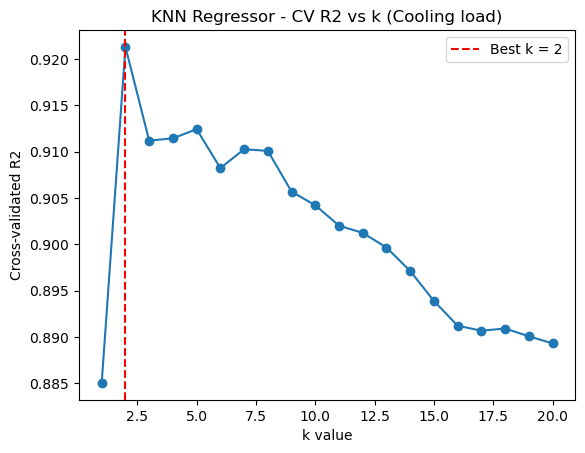

In [26]:
k_values = range(1, 21)
cv_scores = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    scores = cross_val_score(knn, X_train_e_scaled, y_train_e, cv=5, scoring='r2')
    cv_scores.append(scores.mean())

best_k = k_values[np.argmax(cv_scores)]
print(f"Best k: {best_k}, CV R2: {max(cv_scores):.4f}")

plt.plot(k_values, cv_scores, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
plt.xlabel('k value')
plt.ylabel('Cross-validated R2')
plt.title('KNN Regressor - CV R2 vs k (Cooling load)')
plt.legend()
plt.show()

#### Train final model

In [27]:
knn_reg = KNeighborsRegressor(n_neighbors=best_k)
knn_reg.fit(X_train_e_scaled, y_train_e)

y_pred_e = knn_reg.predict(X_test_e_scaled)

#### Performance evaluation

In [28]:
mae = mean_absolute_error(y_test_e, y_pred_e)
mse = mean_squared_error(y_test_e, y_pred_e)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_e, y_pred_e)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

MAE: 1.86
MSE: 8.14
RMSE: 2.85
R2 Score: 0.9127


#### Visualize results

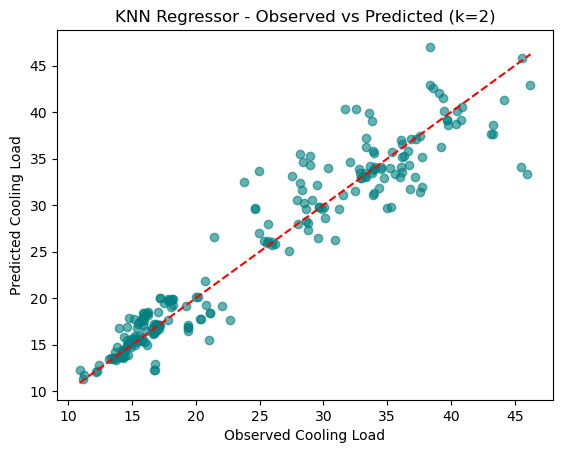

In [29]:
plt.scatter(y_test_e, y_pred_e, color='teal', alpha=0.6)
plt.plot([y_test_e.min(), y_test_e.max()], [y_test_e.min(), y_test_e.max()], color='red', linestyle='--')
plt.xlabel('Observed Cooling Load')
plt.ylabel('Predicted Cooling Load')
plt.title(f'KNN Regressor - Observed vs Predicted (k={best_k})')
plt.show()

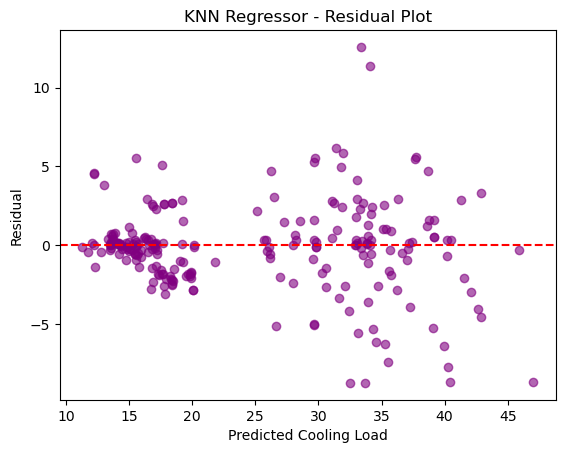

In [30]:
residuals = y_test_e - y_pred_e

plt.scatter(y_pred_e, residuals, color='purple', alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Cooling Load')
plt.ylabel('Residual')
plt.title('KNN Regressor - Residual Plot')
plt.show()

### 2.

### Bernoulli Naive Bayes - Fake news classification

#### Load dataset

In [31]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [32]:
news_train_df = pd.read_csv('Lab 4-31.7.26/train.csv').drop(columns='Unnamed: 0')
news_test_df = pd.read_csv('Lab 4-31.7.26/test.csv').drop(columns='Unnamed: 0')

print(f"Train shape: {news_train_df.shape}, Test shape: {news_test_df.shape}")
news_train_df.head()

Train shape: (17090, 2), Test shape: (4228, 2)


,news,label
0,“Pennsylvania is under a court order to count ...,0
1,“Biden and Democrats have dismantled border se...,0
2,Katie Hobbs “has voted to double our gas tax. ...,1
3,Reuters reported that Nancy Pelosi bought 10 m...,0
4,"It's not true that ""the United States was buil...",0


In [33]:
print("Train label counts:")
print(news_train_df['label'].value_counts())
print()
print("Test label counts:")
print(news_test_df['label'].value_counts())

Train label counts:
label
0    9746
1    7344
Name: count, dtype: int64

Test label counts:
label
0    2399
1    1829
Name: count, dtype: int64


#### Vectorize text

In [34]:
vectorizer = CountVectorizer(max_features=5000, stop_words='english', binary=True)

X_train_news = vectorizer.fit_transform(news_train_df['news'])
X_test_news = vectorizer.transform(news_test_df['news'])

y_train_news = news_train_df['label']
y_test_news = news_test_df['label']

#### Train model

In [35]:
nb_news_model = BernoulliNB()
nb_news_model.fit(X_train_news, y_train_news)

y_train_pred_news = nb_news_model.predict(X_train_news)
y_test_pred_news = nb_news_model.predict(X_test_news)

#### Performance evaluation

In [39]:
train_accuracy = accuracy_score(y_train_news, y_train_pred_news)
test_accuracy = accuracy_score(y_test_news, y_test_pred_news)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")
print()
print("Training Classification Report:")
print(classification_report(y_train_news, y_train_pred_news))
print("Testing Classification Report:")
print(classification_report(y_test_news, y_test_pred_news))

Training Accuracy: 0.7516
Testing Accuracy: 0.7372

Training Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.68      0.76      9746
           1       0.67      0.84      0.74      7344

    accuracy                           0.75     17090
   macro avg       0.76      0.76      0.75     17090
weighted avg       0.77      0.75      0.75     17090

Testing Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.66      0.74      2399
           1       0.65      0.84      0.73      1829

    accuracy                           0.74      4228
   macro avg       0.75      0.75      0.74      4228
weighted avg       0.76      0.74      0.74      4228



#### Visualize results

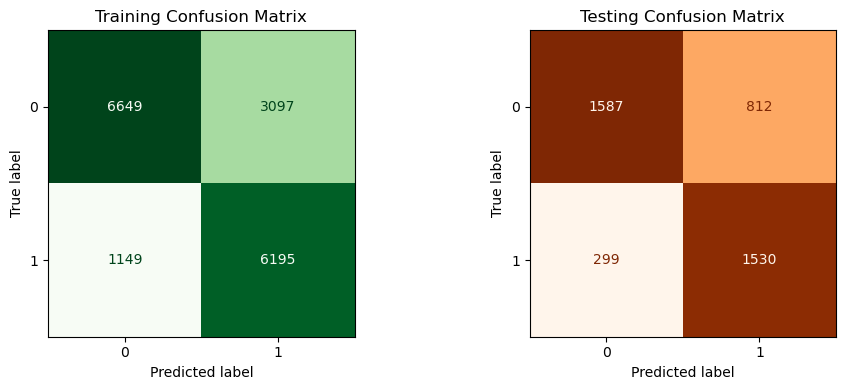

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_train = confusion_matrix(y_train_news, y_train_pred_news)
ConfusionMatrixDisplay(confusion_matrix=cm_train).plot(ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Training Confusion Matrix')

cm_test = confusion_matrix(y_test_news, y_test_pred_news)
ConfusionMatrixDisplay(confusion_matrix=cm_test).plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title('Testing Confusion Matrix')

plt.tight_layout()
plt.show()

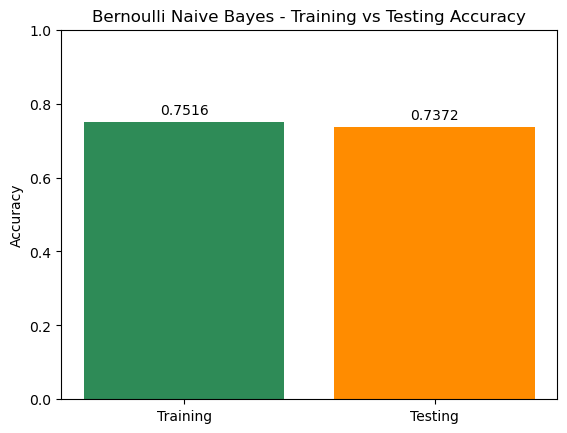

In [41]:
plt.bar(['Training', 'Testing'], [train_accuracy, test_accuracy], color=['seagreen', 'darkorange'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('Bernoulli Naive Bayes - Training vs Testing Accuracy')
for i, acc in enumerate([train_accuracy, test_accuracy]):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center')
plt.show()